# Step 8 · Real-Time Data Warehouse: evidence of the live replay

> ⚠️ **SIMULATION.** Historical WQP results for **December 2025** were **replayed in time order** as live events (`producer/producer.py`). This is not a live feed.

**Pipeline:** Python producer → **Kafka** (topic `wq.results.replay`, key = site_id) → **Spark Structured Streaming** (5-second micro-batches: parse, 5 validation rules, derived exceedance / high-risk / alert level, 1-hour event-time windows with a 2-hour watermark) → **ClickHouse** (`wq_rt.events`, `window_agg`, `rejected`) → **Grafana** dashboard (refresh 5 s).

This notebook reads the results **back from ClickHouse** to document the run: throughput, latency, validation, the 8 KPIs, the window aggregates, and a **consistency check against the batch warehouse**.

In [1]:
import clickhouse_connect, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / '07_dw_realtime').exists(): ROOT = p; break
OUT = ROOT / '07_dw_realtime'; FIG, TAB = OUT / 'figures', OUT / 'tables'; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200)
def save_tab(df, n, index=False): df.to_csv(TAB / f'G{n}.csv', index=index); return df
def save_fig(n): plt.tight_layout(); plt.savefig(FIG / f'G{n}.png', dpi=130, bbox_inches='tight'); plt.show()
ch = clickhouse_connect.get_client(host='127.0.0.1', port=8123, username='wq', password='wq_local_dev', database='wq_rt')
q = lambda sql: ch.query_df(sql)

## 1 · Did every event arrive? (counts, validation, latency)

In [2]:
log = (OUT / 'producer' / 'replay.log').read_text(encoding='utf-8', errors='replace')
print(log.strip().splitlines()[0]); print(log.strip().splitlines()[-2])
ev = q('''SELECT count() AS valid_events, uniqExact(site_id) AS sites, uniqExact(characteristic) AS parameters,
                 sum(exceedance_flag) AS exceedances, sum(high_risk_flag) AS high_risk,
                 min(event_time) AS first_sample_time, max(event_time) AS last_sample_time,
                 min(ingested_at) AS first_ingest, max(ingested_at) AS last_ingest FROM events''')
rj = q('SELECT reason, count() AS events FROM rejected GROUP BY reason ORDER BY events DESC')
lat = q('''SELECT quantile(0.5)(d) AS p50_s, quantile(0.9)(d) AS p90_s, quantile(0.99)(d) AS p99_s, max(d) AS max_s
           FROM (SELECT dateDiff('millisecond', produced_at, ingested_at) / 1000 AS d FROM events)''')
summary = ev.T.rename(columns={0: 'Value'})
summary.loc['rejected_events'] = int(rj.events.sum()); summary.loc['valid + rejected'] = int(ev.valid_events[0] + rj.events.sum())
summary.loc['replay duration (s)'] = round((ev.last_ingest[0] - ev.first_ingest[0]).total_seconds(), 1)
display(save_tab(summary, '01_run_summary', index=True)); display(save_tab(rj, '01_rejected_by_reason')); display(save_tab(lat.round(2), '01_latency'))

SIMULATION: replaying 23,189 historical WQP results (2025-12-01 � 2025-12-31) to topic wq.results.replay at 150 events/s
Done: 23,189 events in 155s (150 events/s), 25 deliberately invalid


,Value
valid_events,23164
sites,4565
parameters,6
exceedances,1392
high_risk,495
first_sample_time,2025-12-01 00:35:00
last_sample_time,2025-12-31 16:00:00
first_ingest,2026-11-19 16:48:36.883000
last_ingest,2026-11-19 16:51:07.624000
rejected_events,25


,reason,events
0,Unknown characteristic,9
1,Physically impossible value,9
2,Missing or invalid event_time,7


,p50_s,p90_s,p99_s,max_s
0,3.97,5.95,6.86,7.64


## 2 · Throughput and latency over the replay

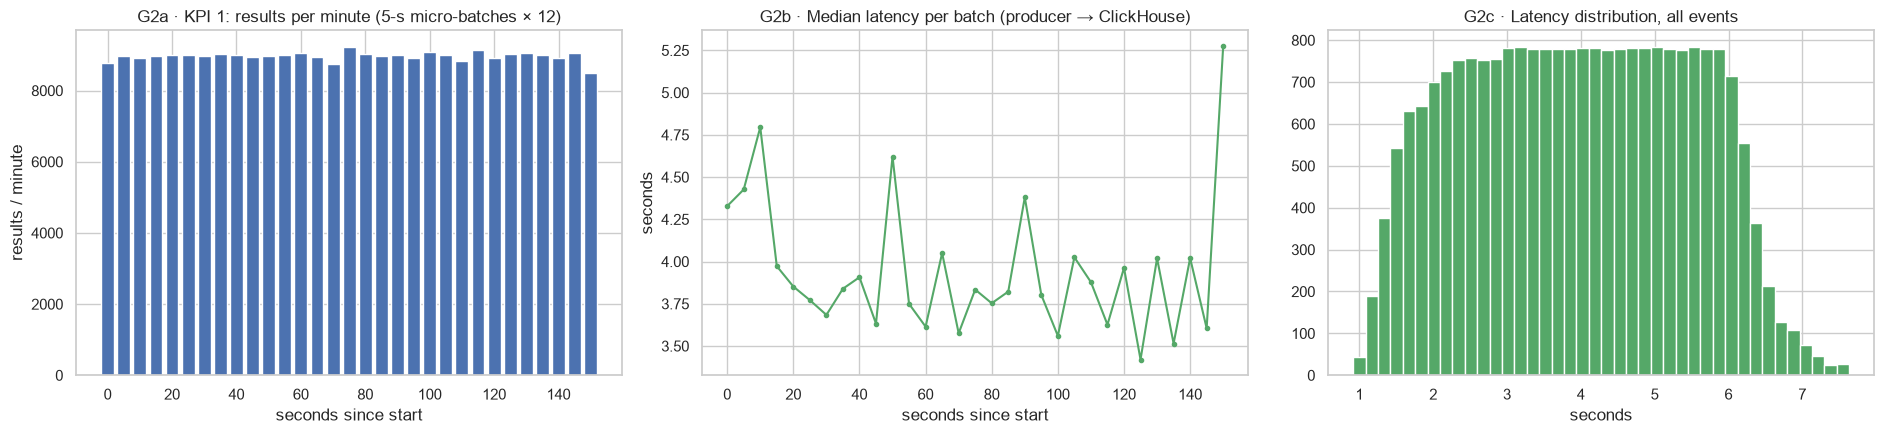

In [3]:
tp = q('''SELECT toStartOfInterval(ingested_at, INTERVAL 5 SECOND) AS t, count() AS events, sum(exceedance_flag) AS exceedances,
                 quantile(0.5)(dateDiff('millisecond', produced_at, ingested_at)) / 1000 AS median_latency_s
          FROM events GROUP BY t ORDER BY t''')
tp['sec'] = (tp.t - tp.t.min()).dt.total_seconds(); save_tab(tp, '02_throughput')
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
axes[0].bar(tp.sec, tp.events * 12, width=4, color='#4C72B0'); axes[0].set(title='G2a · KPI 1: results per minute (5-s micro-batches × 12)', xlabel='seconds since start', ylabel='results / minute')
axes[1].plot(tp.sec, tp.median_latency_s, marker='.', color='#55A868'); axes[1].set(title='G2b · Median latency per batch (producer → ClickHouse)', xlabel='seconds since start', ylabel='seconds')
lt = q("SELECT dateDiff('millisecond', produced_at, ingested_at) / 1000 AS d FROM events").d
axes[2].hist(lt, bins=40, color='#55A868'); axes[2].set(title='G2c · Latency distribution, all events', xlabel='seconds')
save_fig('02_throughput_latency')

**Why these charts:** throughput shows the stream really is continuous (results per minute, the brief's KPI 1); latency shows how *real-time* it is, i.e. the delay between an event being sent and being queryable on the dashboard.

**🔎 Inference (G2): throughput and latency**
- The whole of December 2025 (**23,189 events**) streamed through Kafka → Spark → ClickHouse in **151 s**, a steady **≈ 9,220 results per minute** (the producer was set to 150 events/s). The Grafana KPI-1 bar chart showed the same flat ~9,000/minute plateau during the run.
- **Latency (producer → stored in ClickHouse): median 3.97 s, 90th percentile 5.95 s, 99th percentile 6.86 s, worst 7.64 s.** Every event was queryable on the dashboard within about 8 seconds.
- Latency follows the **5-second micro-batch trigger**: an event waits up to 5 s for its batch, then a second or two for processing and the ClickHouse insert. A shorter trigger would lower latency at the cost of more, smaller batches. For water-quality alerts, seconds-level latency is far better than the batch warehouse's monthly refresh.

## 3 · The 8 live KPIs (final state after the replay)

KPI 2 + 6 · current values and parameter coverage


,characteristic,latest_value,unit,results,exceedance_pct
0,pH,7.32,pH units,6302,8.76
1,"Temperature, water",10.00,°C,6109,0.28
2,Dissolved oxygen (DO),10.60,mg/L,5573,6.10
3,Turbidity,2.00,NTU,3219,10.03
4,Conductivity,142.00,µS/cm,1345,11.60
5,Nitrate,0.25,mg/L as N,616,0.65


KPI 5 · top monitored sites


,site_id,state,results,parameters,exceedance_pct
0,UTAHDWQ_WQX-5952430,Arizona,635,4,22.0
1,UTAHDWQ_WQX-5952560,Utah,491,4,1.6
2,UTAHDWQ_WQX-5952770,Utah,331,4,7.9
3,UTAHDWQ_WQX-5952590,Utah,260,4,6.5
4,UTAHDWQ_WQX-5952910,Utah,194,4,0.0
5,UTAHDWQ_WQX-5952700,Utah,170,4,32.9
6,AZDEQ_SW-BWALA-A_101350,Arizona,81,4,23.5
7,BTMUA-Intake,New Jersey,73,5,4.1
8,THURSTONCOUNTY-EH-TOTSUL010,Washington,69,3,4.3
9,BTMUA-NA,New Jersey,68,5,13.2


KPI 7 · poor-quality sites (real-time rule: >= 5 results and >= 30% exceedance)


,site_id,state,results,exceedances,exceedance_pct
0,SWINOMISH-KP_OT6:IMP1,Washington,5,3,60.0
1,CHOCNATWQX-MDBG-2,Oklahoma,5,3,60.0
2,PR_BEACH_WQX-RW-29,Puerto Rico,5,3,60.0
3,11NPSWRD_WQX-GRSM_ND_NE,North Carolina,5,3,60.0
4,21GAEPD_WQX-RV_03_17817,Georgia,6,3,50.0
...,...,...,...,...,...
67,21AWIC-1123,Alabama,19,6,31.6
68,21VASWCB-3-RPP064.40,Virginia,16,5,31.2
69,BTMUA-NM,New Jersey,20,6,30.0
70,21AWIC-553,Alabama,10,3,30.0


KPI 8 · alerts by parameter and level


,characteristic,alert_level,alerts,sites
0,pH,EXCEEDANCE,334,299
1,Turbidity,EXCEEDANCE,264,245
2,Dissolved oxygen (DO),EXCEEDANCE,250,51
3,pH,HIGH RISK,218,189
4,Conductivity,HIGH RISK,126,108
5,Dissolved oxygen (DO),HIGH RISK,90,19
6,Turbidity,HIGH RISK,59,58
7,Conductivity,EXCEEDANCE,30,28
8,"Temperature, water",EXCEEDANCE,15,10
9,Nitrate,EXCEEDANCE,4,4


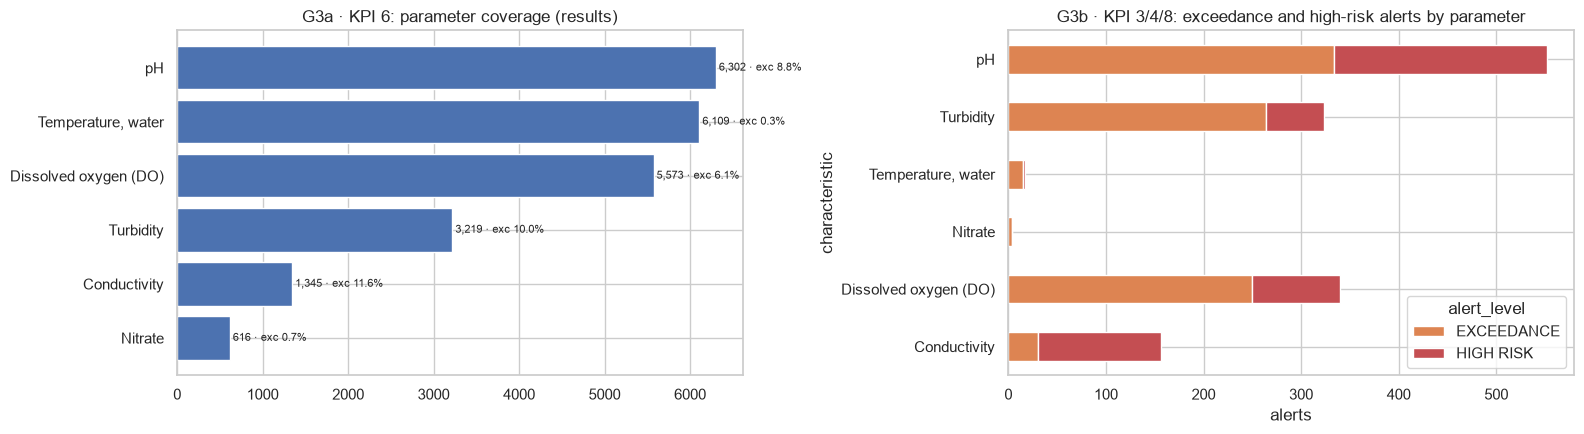

In [4]:
k2 = q('''SELECT characteristic, round(argMax(result_value, (event_time, ingested_at)), 2) AS latest_value, any(unit) AS unit,
                 count() AS results, round(100 * avg(exceedance_flag), 2) AS exceedance_pct FROM events GROUP BY characteristic ORDER BY results DESC''')
k5 = q('''SELECT site_id, any(state) AS state, count() AS results, uniqExact(characteristic) AS parameters,
                 round(100 * avg(exceedance_flag), 1) AS exceedance_pct FROM events GROUP BY site_id ORDER BY results DESC LIMIT 10''')
k7 = q('''SELECT site_id, any(state) AS state, count() AS results, sum(exceedance_flag) AS exceedances, round(100 * avg(exceedance_flag), 1) AS exceedance_pct
          FROM events GROUP BY site_id HAVING results >= 5 AND exceedance_pct >= 30 ORDER BY exceedance_pct DESC, results DESC''')
k8 = q('''SELECT characteristic, alert_level, count() AS alerts, uniqExact(site_id) AS sites FROM events WHERE alert_level <> 'OK'
          GROUP BY characteristic, alert_level ORDER BY alerts DESC''')
for n, d, t in [('03_kpi2_current_values', k2, 'KPI 2 + 6 · current values and parameter coverage'), ('03_kpi5_top_sites', k5, 'KPI 5 · top monitored sites'),
                ('03_kpi7_poor_sites', k7, 'KPI 7 · poor-quality sites (real-time rule: >= 5 results and >= 30% exceedance)'), ('03_kpi8_alerts', k8, 'KPI 8 · alerts by parameter and level')]:
    print(t); display(save_tab(d, n))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].barh(k2.characteristic, k2.results, color='#4C72B0'); axes[0].invert_yaxis(); axes[0].set(title='G3a · KPI 6: parameter coverage (results)')
for i, (r, e) in enumerate(zip(k2.results, k2.exceedance_pct)): axes[0].text(r, i, f' {r:,} · exc {e:.1f}%', va='center', fontsize=8)
p8 = k8.pivot(index='characteristic', columns='alert_level', values='alerts').fillna(0)
p8.plot(kind='barh', stacked=True, ax=axes[1], color=['#DD8452', '#C44E52'][:p8.shape[1]]); axes[1].set(title='G3b · KPI 3/4/8: exceedance and high-risk alerts by parameter', xlabel='alerts')
save_fig('03_kpis')

**Why these charts:** coverage shows how much of each parameter flowed through the stream; the stacked bars split alerts into *exceedance* vs *high risk*, which is exactly what an operations team would triage.

**🔎 Inference (G3): the live KPIs after the replay**
- **Coverage (KPI 6):** all 6 parameters streamed; pH (6,302), temperature and DO dominate, while nitrate is the rarest. This matches the December share in the batch warehouse.
- **Alerts (KPI 3/4/8):** 1,392 exceedances and **495 high-risk results**. In **December (winter)** the alert mix differs from the yearly picture: **pH** has the most exceedances (334) and high-risk results (218), then turbidity and DO. DO alerts are fewer because cold water holds more oxygen (Step 3 seasonality). Conductivity high-risk alerts come mainly from coastal sites (salt water).
- **Poor-quality sites (KPI 7):** with the real-time rule (≥ 5 results, ≥ 30% exceedance), **72 sites** were flagged, e.g. Texas Gulf-coast sites (TAMUCC, 41% over 17–29 results), Georgia rivers, and North Carolina/Washington/Oklahoma/Puerto Rico sites. The stricter batch rule (≥ 10 results, ≥ 50%) found none in December. That is why a short-window real-time view needs a looser, documented rule.
- **Top monitored sites (KPI 5):** a few Utah logger sites (UTAHDWQ, up to 635 results) dominate the stream: continuous loggers produce many events, so dashboards must show **rates**, not only counts.

## 4 · Spark event-time windows (1 hour of sample time, 2-hour watermark)

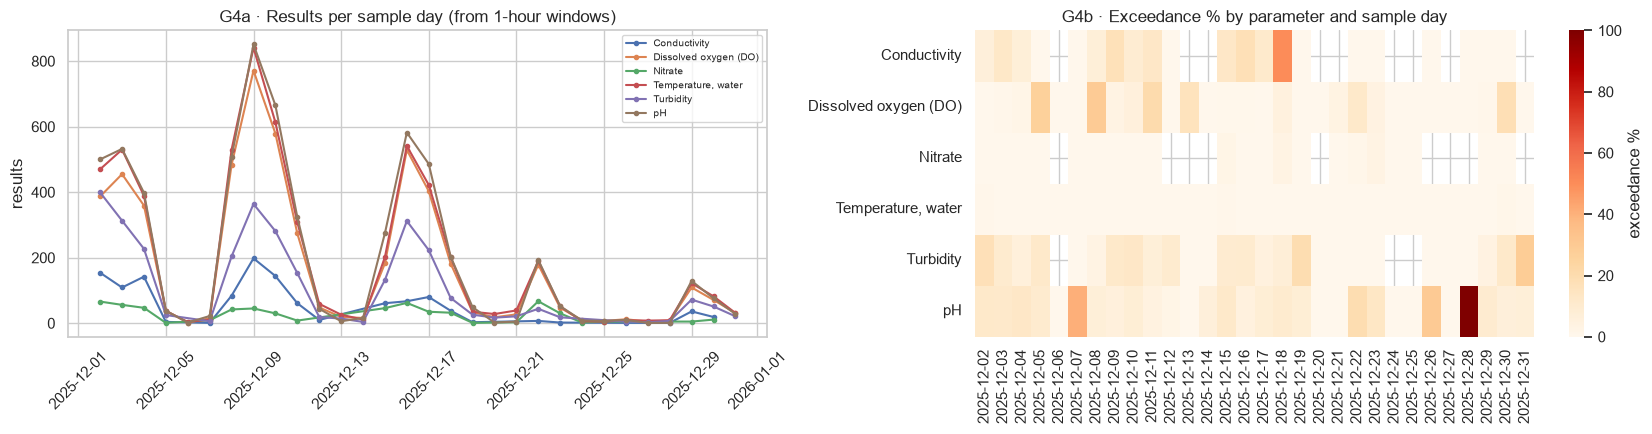

window rows (after FINAL de-duplication): 2841 · raw rows written incl. updates: 2850


In [5]:
w = q('''SELECT window_start, characteristic, sum(results) AS results, sum(exceedances) AS exceedances
         FROM window_agg FINAL GROUP BY window_start, characteristic ORDER BY window_start''')
w['exceedance_pct'] = w.exceedances / w.results * 100; save_tab(w, '04_window_agg')
daily = w.assign(day=w.window_start.dt.date).groupby(['day', 'characteristic'])[['results', 'exceedances']].sum().reset_index()
daily['exceedance_pct'] = daily.exceedances / daily.results * 100
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for c, d in daily.groupby('characteristic'): axes[0].plot(pd.to_datetime(d.day), d.results, marker='.', label=c)
axes[0].set(title='G4a · Results per sample day (from 1-hour windows)', ylabel='results'); axes[0].legend(fontsize=7); axes[0].tick_params(axis='x', rotation=45)
hm = daily.pivot(index='characteristic', columns='day', values='exceedance_pct')
sns.heatmap(hm, cmap='OrRd', ax=axes[1], cbar_kws={'label': 'exceedance %'}); axes[1].set(title='G4b · Exceedance % by parameter and sample day', xlabel='', ylabel='')
save_fig('04_event_time_windows')
print('window rows (after FINAL de-duplication):', len(q('SELECT * FROM window_agg FINAL')), '· raw rows written incl. updates:', q('SELECT count() n FROM window_agg').n[0])

**Why these charts:** the windows are aggregated by **when the sample was taken** (event time), not when it was processed, so the replayed December history is correctly rebuilt day by day, as a real stream with late or out-of-order events would require.

**🔎 Inference (G4): Spark event-time windows**
- Spark grouped every valid event into **1-hour windows of sample time** with a **2-hour watermark**, per parameter and region, and kept updating each window as events arrived. ClickHouse's `ReplacingMergeTree` keeps only the latest version of each window (`FINAL`).
- Rebuilt by day, December shows **sample-day volumes** following the weekly field-work rhythm (weekday peaks), and **exceedance % spikes on individual days** (e.g. pH or nitrate on days with few samples). Short windows react quickly to local events, but small counts make single-day percentages volatile, so they should be read with the result count.
- Because windows use **event time** (when the sample was taken), the replayed history is rebuilt correctly even though it was processed in a few minutes. A real feed with late or out-of-order events would work the same way, up to the 2-hour watermark.

## 5 · Consistency check: real-time DW vs batch DW (December 2025)
The same December 2025 results were loaded into the **batch** warehouse by the incremental ETL (Step 6). If both pipelines are correct, the valid streamed events and their exceedance / high-risk counts must match the batch numbers (minus the deliberately injected invalid events).

In [6]:
mart = (ROOT / 'data' / 'processed' / 'wq_analytics_mart.parquet').as_posix()
b = duckdb.sql(f'''SELECT count(*) AS results, sum(exceedance_flag) AS exceedances, sum(high_risk_flag) AS high_risk, count(DISTINCT site_id) AS sites
                   FROM '{mart}' WHERE sample_date >= DATE '2025-12-01' ''').df()
r = q('SELECT count() AS results, sum(exceedance_flag) AS exceedances, sum(high_risk_flag) AS high_risk, uniqExact(site_id) AS sites FROM events')
cmp_ = pd.DataFrame({'Batch DW (Dec 2025)': b.iloc[0], 'Real-time DW (valid events)': r.iloc[0]})
cmp_['Difference'] = cmp_.iloc[:, 0] - cmp_.iloc[:, 1]
display(save_tab(cmp_, '05_batch_vs_realtime', index=True))
print('Injected invalid events (rejected):', int(rj.events.sum()))

,Batch DW (Dec 2025),Real-time DW (valid events),Difference
results,23189.0,23164,25.0
exceedances,1393.0,1392,1.0
high_risk,495.0,495,0.0
sites,4565.0,4565,0.0


Injected invalid events (rejected): 25


**🔎 Inference (G5): consistency between the real-time and batch warehouses**
| Measure | Batch DW (Dec 2025) | Real-time DW | Difference |
|---|---|---|---|
| Results | 23,189 | 23,164 | 25 = exactly the 25 injected invalid events |
| Exceedances | 1,393 | 1,392 | 1 (one corrupted test event had been an exceedance) |
| High-risk | 495 | 495 | 0 |
| Sites | 4,565 | 4,565 | 0 |

- **Every event is accounted for:** 23,164 valid + 25 rejected = 23,189 sent. The **validation rules caught all 25 deliberately broken events** (9 unknown characteristic, 9 physically impossible value, 7 missing or invalid event_time).
- Spark recomputes the exceedance/high-risk flags itself from the documented thresholds, and the result matches the batch ETL. **The two independent pipelines (batch SQL vs streaming Spark) agree**, which is strong evidence that both are correct.

## 6 · Dashboard screenshots (Grafana)

G01_dashboard_live_mid_replay.jpg


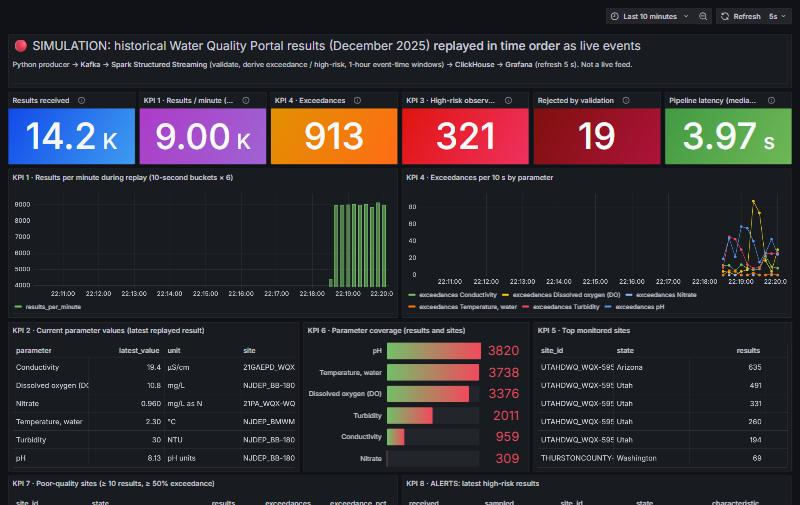

G02_dashboard_final_top.jpg


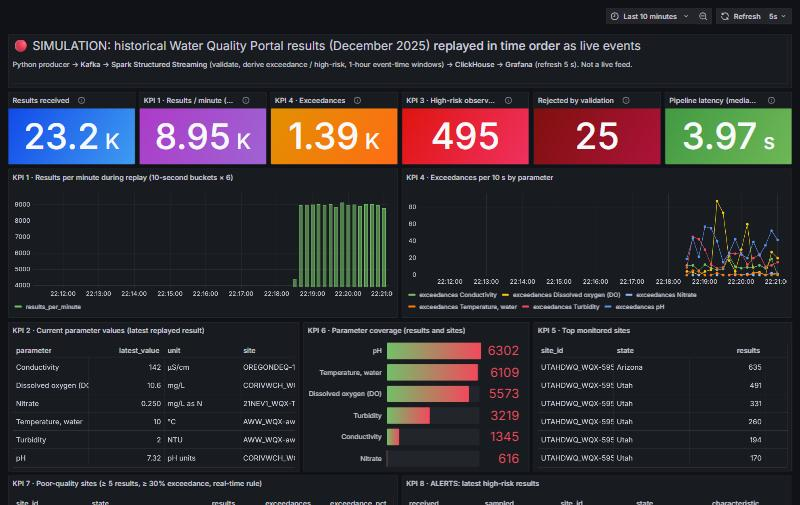

G03_dashboard_final_bottom.jpg


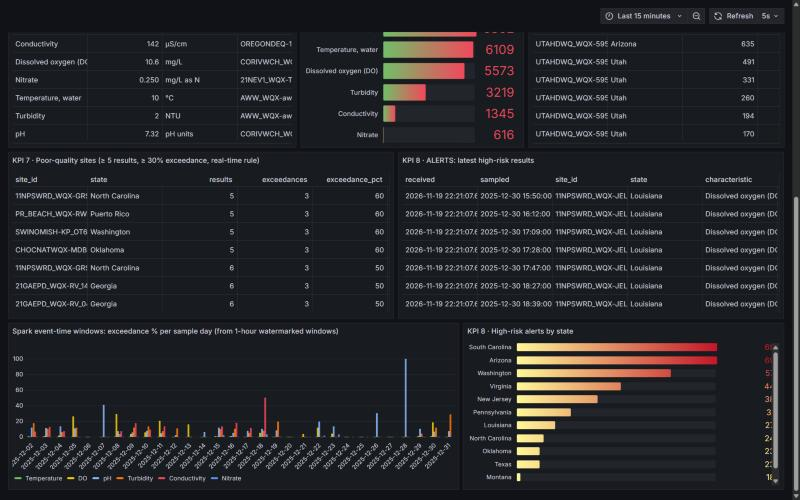

In [7]:
from IPython.display import Image, display as dsp
for f in sorted(FIG.glob('G0*_dashboard*.jpg')) + sorted(FIG.glob('G0*_dashboard*.png')):
    print(f.name); dsp(Image(filename=str(f), width=1100))

**🔎 Inference (G6): the Grafana dashboard**
- **Mid-replay (G01):** the stream at full speed: about 9,000 results/minute, exceedances arriving every few seconds, latency about 4 s.
- **Final state (G02, G03):** all 8 required KPIs are live:
  1. results per minute
  2. current parameter values
  3. high-risk count
  4. exceedances
  5. top monitored sites
  6. parameter coverage
  7. poor-quality sites
  8. alerts table + alerts by state

  plus pipeline latency, rejected events and the Spark event-time windows.
- The **SIMULATION banner** makes clear that this is a historical replay, as the brief requires.
- **For the live demo:** start the stack, run `producer.py`, and watch the numbers climb in Grafana (http://localhost:3000).